## Whats a Layer in Neural Networks?
This is often confusing if the stack of neurons in the visualisation a layer or the connections between them. We will use the PyTorch implementation to clarify this.

In [14]:
import torch
import torch.nn as nn

In [4]:
layer = nn.Linear(in_features=2, out_features=3)

In [5]:
print(layer)

Linear(in_features=2, out_features=3, bias=True)


In [13]:
print(f"Weight matrix: {layer.weight}")

Weight matrix: Parameter containing:
tensor([[ 0.6307,  0.3863],
        [-0.4045, -0.0893],
        [-0.1790,  0.6179]], requires_grad=True)


In [12]:
print(f"Weight shape: {layer.weight.shape}")

Weight shape: torch.Size([3, 2])


In [20]:
input_data = torch.tensor([[1.0, 2.0]]) # shape: [batch_size: 1, in_features=2]
outputs = layer(input_data)
print("Outputs: ", outputs)
print("Outputs shape: ", outputs.shape) # shape: [batch_size: 1, out_features=3]


Outputs:  tensor([[ 1.3392, -0.5049,  0.9462]], grad_fn=<AddmmBackward0>)
Outputs shape:  torch.Size([1, 3])


### Visualize network layers
Here is a utility function to visualize layers of a neural network using Matplotlib. This helps understanding one single layer as well as multi-layer perceptrons (MLPs) with deep architectures. So we understand what a layer is in neural networks.


In [ ]:
# pip install matplotlib torch  # (graphviz NOT required)
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

def _weights_from_model(model: nn.Module):
    """Return (layer_sizes, Ws, bs) for all nn.Linear layers in forward order."""
    sizes, Ws, bs = [], [], []
    prev = None
    for m in model.modules():
        if isinstance(m, nn.Linear):
            W = m.weight.detach().cpu().numpy()           # (out, in)
            b = m.bias.detach().cpu().numpy() if m.bias is not None else None
            Ws.append(W); bs.append(b)
            if prev is None:
                sizes.append(W.shape[1])                  # in_features of first Linear
            sizes.append(W.shape[0])                      # out_features of this Linear
            prev = W
    if not Ws:
        raise ValueError("No nn.Linear layers found.")
    return sizes, Ws, bs

def visualize_mlp(model: nn.Module,
                  neuron_radius=0.15, hgap=2.6, vgap=1.0,
                  max_edges=4000, filename=None, title=None):
    """
    Draw a node-and-edges diagram for a model’s Linear layers.
    - thickness ∝ |weight|
    - dashed = negative weights
    - caps edges at max_edges for huge layers (sampling)
    """
    layer_sizes, Ws, _ = _weights_from_model(model)
    L = len(layer_sizes)

    # Coordinates for neurons
    coords = []
    for li, n in enumerate(layer_sizes):
        ys = np.linspace(-(n-1)*vgap/2, (n-1)*vgap/2, n) if n > 1 else np.array([0.0])
        xs = np.full(n, li*hgap)
        coords.append(list(zip(xs, ys)))

    # Normalize thickness by global |w|
    all_abs = np.concatenate([np.abs(W).ravel() for W in Ws])
    wmax = all_abs.max() if all_abs.size else 1.0

    fig, ax = plt.subplots(figsize=(2 + 2.2*L, 1.4*max(layer_sizes)+1))

    # Draw connections (optionally sample if too many)
    rng = np.random.default_rng(0)
    for li in range(L-1):
        left = coords[li]; right = coords[li+1]; W = Ws[li]
        pairs = [(i, j) for i in range(len(left)) for j in range(len(right))]
        if len(pairs) > max_edges:
            pairs = rng.choice(pairs, size=max_edges, replace=False).tolist()
        for i, j in pairs:
            (xL, yL), (xR, yR) = left[i], right[j]
            w = W[j, i]
            lw = 0.6 + 3.4 * (abs(w) / (wmax if wmax > 0 else 1.0))
            ls = '--' if w < 0 else '-'
            alpha = 0.3 + 0.7 * (abs(w) / (wmax if wmax > 0 else 1.0))
            ax.plot([xL+neuron_radius, xR-neuron_radius], [yL, yR],
                    linewidth=lw, linestyle=ls, alpha=alpha)

    # Draw neurons
    for li, layer in enumerate(coords):
        for ni, (x, y) in enumerate(layer):
            ax.add_patch(Circle((x, y), radius=neuron_radius, fill=False, linewidth=2))
            if li == 0:
                ax.text(x - neuron_radius - 0.25, y, f"x{ni+1}", ha='right', va='center', fontsize=11)
            elif li == L-1:
                ax.text(x + neuron_radius + 0.25, y, f"y{ni+1}", ha='left', va='center', fontsize=11)
            else:
                ax.text(x, y, f"h{ni+1}", ha='center', va='center', fontsize=9)

        header = "Input" if li == 0 else ("Output" if li == L-1 else "Hidden")
        ax.text(layer[0][0], max(y for _, y in layer)+neuron_radius+0.5, header,
                ha='center', va='bottom', fontsize=13)

    ax.text(coords[0][0][0], min(y for _, y in coords[0]) - (neuron_radius+1.0),
            "Edge thickness ∝ |weight|    Dashed = negative", fontsize=10)

    ax.set_aspect('equal'); ax.axis('off')
    ax.set_xlim(-1.0, (L-1)*hgap + 1.0)
    y_min = min(min(y for _, y in layer) for layer in coords) - 1.2
    y_max = max(max(y for _, y in layer) for layer in coords) + 1.2
    ax.set_ylim(y_min, y_max)
    if title: ax.set_title(title, pad=16)
    if filename: plt.savefig(filename, bbox_inches='tight')
    plt.show()

# --- Usage examples ---
# 1) Simple layer: 2 → 4
# visualize_mlp(nn.Sequential(nn.Linear(2, 4, bias=True)), title="2 → 4")

# 2) Classic MLP: 3 → 5 → 2
# model = nn.Sequential(nn.Linear(3, 5), nn.ReLU(), nn.Linear(5, 2))
# visualize_mlp(model, title="3 → 5 → 2", filename="mlp_3_5_2.svg")

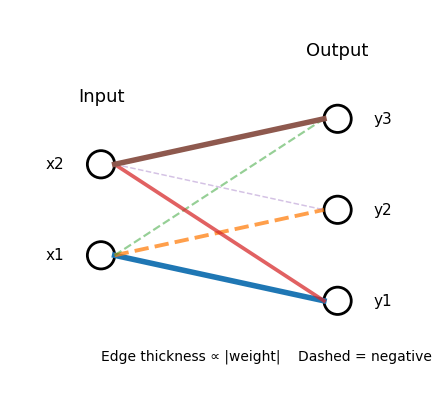

In [35]:
# One single layer -> Here inputs (in_features) and outputs (out_features) are stacked neurons!
visualize_mlp(layer)

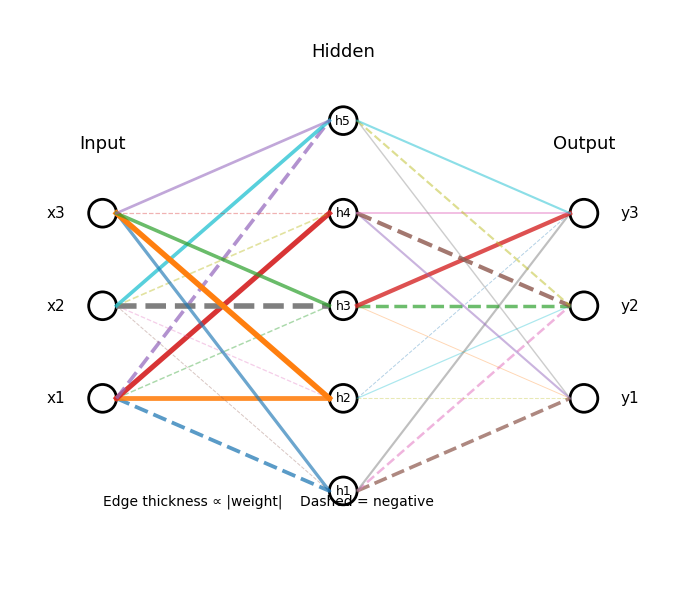

In [36]:
visualize_mlp(nn.Sequential(nn.Linear(3, 5), nn.ReLU(), nn.Linear(5, 3)))

### Takeaway
Looking at the visualizations above, we can conclude that:
- A layer in a neural network consists two stacks of neurons (input and output) connected by weights. Which is often misunderstood as just the one single stack of neurons. If we consider a neuron stack as a layer, then there will always be same number of inputs and outputs. which is not true. Therefore, a layer is defined by the connections (weights) between two stacks of neurons where the first stack represents the inputs and the second stack represents the outputs which could be of different sizes.
- In case deeper networks (MLPs) we have multiple layers and two layers can only be connected if the output size of the first layer matches the input size of the second layer. And therefore the hidden layers are only represented once due to having the same size for two adjacent layers.